In [ ]:
import numpy as np
import random  

In [ ]:
# Model parameters
n = 101                  # Number of customers and possible positions
D = 1.0                  # Total demand
c0 = 0.2                 # Cost per pizza
k = 1.0                  # Travel cost
p_max = 40           # Maximum price
dp = 0.05                # Price step

p1 = 20.0
p2 = 20.0

demand_per_customer = D / n

# Discrete road and customers
road = np.linspace(-1, 1, n)

# Initial positions
x1 = random.choice(road)
x2 = random.choice(road)

In [ ]:
# Calculate profits with price competition
def calculate_profit(x1, x2, p1, p2):
    total_cost_1 = p1 + k * np.abs(road - x1)
    total_cost_2 = p2 + k * np.abs(road - x2)

    customers_1 = np.sum(total_cost_1 < total_cost_2)
    customers_2 = np.sum(total_cost_2 < total_cost_1)

    ties = np.sum(np.isclose(total_cost_1, total_cost_2))

    customers_1 += 0.5 * ties
    customers_2 += 0.5 * ties

    Q1 = customers_1 * demand_per_customer
    Q2 = customers_2 * demand_per_customer

    profit_1 = (p1 - c0) * Q1
    profit_2 = (p2 - c0) * Q2

    return profit_1, profit_2

In [ ]:
def best_price(x1, x2, p1, p2, firm):
    current_price = p1 if firm == 1 else p2
    best_price = current_price

    if firm == 1:
        best_profit = calculate_profit(x1, x2, p1, p2)[0]
    else:
        best_profit = calculate_profit(x1, x2, p1, p2)[1]

    for new_price in [current_price - dp, current_price + dp]:

        if 0 <= new_price <= p_max:

            if firm == 1:
                new_profit = calculate_profit(x1, x2, new_price, p2)[0]
            else:
                new_profit = calculate_profit(x1, x2, p1, new_price)[1]

            if new_profit > best_profit:
                best_profit = new_profit
                best_price = new_price

    return best_price

In [ ]:
# Adjust prices until neither firm wants to change price
def price_equilibrium(x1, x2, p1, p2):

    for iteration in range(1000):
        old_p1, old_p2 = p1, p2

        p1 = best_price(x1, x2, old_p1, old_p2, 1)
        p2 = best_price(x1, x2, old_p1, old_p2, 2)

        if np.isclose(p1, old_p1) and np.isclose(p2, old_p2):
            break

    return p1, p2

In [ ]:
def best_location(x1, x2, p1, p2, firm):
    current_position = x1 if firm == 1 else x2
    current_index = np.where(road == current_position)[0][0]

    best_position = current_position
    best_profit = calculate_profit(x1, x2, p1, p2)[0] if firm == 1 else calculate_profit(x1, x2, p1, p2)[1]

    for new_index in [current_index - 1, current_index + 1]:
        if 0 <= new_index < len(road):

            new_position = road[new_index]

            if firm == 1:
                new_p1, new_p2 = price_equilibrium(new_position, x2, p1, p2)
                new_profit = calculate_profit(new_position, x2, new_p1, new_p2)[0]
            else:
                new_p1, new_p2 = price_equilibrium(x1, new_position, p1, p2)
                new_profit = calculate_profit(x1, new_position, new_p1, new_p2)[1]

            if new_profit > best_profit:
                best_profit = new_profit
                best_position = new_position

    return best_position

In [ ]:
# Save position history
history_1 = [x1]
history_2 = [x2]

# Outer loop: adjust locations
for location_iteration in range(1000):
    old_x1, old_x2 = x1, x2

    # Find price equilibrium for current locations
    p1, p2 = price_equilibrium(x1, x2, p1, p2)

    # Adjust locations
    x1 = best_location(old_x1, old_x2, p1, p2, 1)
    x2 = best_location(old_x1, old_x2, p1, p2, 2)

    # Save positions


In [ ]:
    history_1.append(x1)
    history_2.append(x2)

    # Stop if neither firm changes location
    if x1 == old_x1 and x2 == old_x2:
        break

# Find final price equilibrium
p1, p2 = price_equilibrium(x1, x2, p1, p2)

# Calculate final profits
profit_1, profit_2 = calculate_profit(x1, x2, p1, p2)

# Print results
print(f"Number of location iterations: {location_iteration + 1}")
print(f"Firm 1 final position: {x1:.2f}")
print(f"Firm 2 final position: {x2:.2f}")
print(f"Firm 1 final price: {p1:.2f}")
print(f"Firm 2 final price: {p2:.2f}")
print(f"Firm 1 profit: {profit_1:.3f}")
print(f"Firm 2 profit: {profit_2:.3f}")

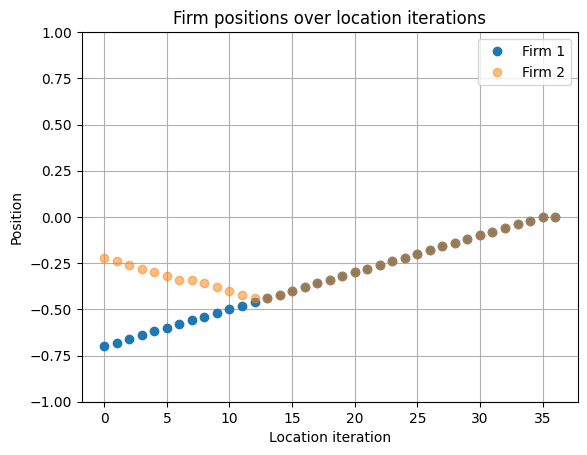

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_1, marker="o", linestyle="None", label="Firm 1")
plt.plot(history_2, marker="o", linestyle="None", label="Firm 2", alpha=0.5)

plt.xlabel("Location iteration")
plt.ylabel("Position")
plt.title("Firm positions over location iterations")

plt.ylim(-1, 1)
plt.legend()
plt.grid()

plt.show()